# Bài 1 – Tabular: Dự đoán xe "lemon" (Kick) trong đấu giá xe cũ
**Môn:** Nền tảng lập trình cho phân tích và trực quan dữ liệu – HK 261 (2026–2027) · **GV:** Lê Thành Sách
**Nhóm:** BugIsFeature · **Sinh viên:** Nguyễn Thị Cẩm Vân · **MSSV:** 2570803
**Hình thức:** cá nhân · **Loại dữ liệu:** Tabular (bắt buộc)

## 1. Mô tả bài toán và tập dữ liệu
- **Nguồn:** OpenML `kick` (cuộc thi Kaggle *Don't Get Kicked!* của Carvana).
- **Bài toán:** phân loại nhị phân `IsBadBuy` – xe mua ở đấu giá có phải "lemon" (lỗi nặng, mua hỏng) hay không.
- **Quy mô:** 72.983 dòng × 33 cột (> 2000 dòng, > 10 cột).
- **Vì sao khó:** (1) **mất cân bằng lớp** (~12% là lemon), (2) **nhiều missing value**, (3) **outlier** ở giá/số km, (4) nhiều cột categorical có **cardinality cao** (Model ~1000 giá trị).
- **Metric chính:** do lớp lệch nên *không* dùng accuracy một mình mà dùng **F1, ROC-AUC, PR-AUC, Balanced Accuracy**.

**Quy trình:** Mô tả → EDA → Tiền xử lý (missing, outlier, encoding, scaling, split) → Mô hình sklearn → So sánh → Kết luận.

In [1]:
import warnings, sys
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px, plotly.graph_objects as go, plotly.io as pio
from IPython.display import display, Markdown
if "google.colab" not in sys.modules:
    pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42
def note(text):
    """Hiển thị caption/kết luận (Markdown) sinh từ số liệu thực tế."""
    display(Markdown(text))

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, roc_auc_score, average_precision_score, balanced_accuracy_score,
                             precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve)
from sklearn.inspection import permutation_importance

In [2]:
raw = fetch_openml("kick", as_frame=True, parser="auto").frame.copy()
raw["IsBadBuy"] = pd.to_numeric(raw["IsBadBuy"].astype(str)).astype(int)
raw["PurchDate"] = pd.to_datetime(raw["PurchDate"], unit="s")
# Các cột "mã" (ID) giữ dạng categorical, các cột category còn lại là chuỗi
for c in raw.columns:
    if str(raw[c].dtype) == "category":
        raw[c] = raw[c].astype(object)
print("Kích thước:", raw.shape)
raw.head()

Kích thước: (72983, 33)


,IsBadBuy,PurchDate,Auction,VehYear,VehicleAge,Make,Model,Trim,SubModel,Color,Transmission,WheelTypeID,WheelType,VehOdo,Nationality,Size,TopThreeAmericanName,MMRAcquisitionAuctionAveragePrice,MMRAcquisitionAuctionCleanPrice,MMRAcquisitionRetailAveragePrice,MMRAcquisitonRetailCleanPrice,MMRCurrentAuctionAveragePrice,MMRCurrentAuctionCleanPrice,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART,BYRNO,VNZIP1,VNST,VehBCost,IsOnlineSale,WarrantyCost
0,0,2009-12-07,ADESA,2006,3,MAZDA,MAZDA3,i,4D SEDAN I,RED,AUTO,1,Alloy,89046,OTHER ASIAN,MEDIUM,OTHER,8155.0,9829.0,11636.0,13600.0,7451.0,8552.0,11597.0,12409.0,NaN,NaN,21973,33619,FL,7100.0,0,1113
1,0,2009-12-07,ADESA,2004,5,DODGE,1500 RAM PICKUP 2WD,ST,QUAD CAB 4.7L SLT,WHITE,AUTO,1,Alloy,93593,AMERICAN,LARGE TRUCK,CHRYSLER,6854.0,8383.0,10897.0,12572.0,7456.0,9222.0,11374.0,12791.0,NaN,NaN,19638,33619,FL,7600.0,0,1053
2,0,2009-12-07,ADESA,2005,4,DODGE,STRATUS V6,SXT,4D SEDAN SXT FFV,MAROON,AUTO,2,Covers,73807,AMERICAN,MEDIUM,CHRYSLER,3202.0,4760.0,6943.0,8457.0,4035.0,5557.0,7146.0,8702.0,NaN,NaN,19638,33619,FL,4900.0,0,1389
3,0,2009-12-07,ADESA,2004,5,DODGE,NEON,SXT,4D SEDAN,SILVER,AUTO,1,Alloy,65617,AMERICAN,COMPACT,CHRYSLER,1893.0,2675.0,4658.0,5690.0,1844.0,2646.0,4375.0,5518.0,NaN,NaN,19638,33619,FL,4100.0,0,630
4,0,2009-12-07,ADESA,2005,4,FORD,FOCUS,ZX3,2D COUPE ZX3,SILVER,MANUAL,2,Covers,69367,AMERICAN,COMPACT,FORD,3913.0,5054.0,7723.0,8707.0,3247.0,4384.0,6739.0,7911.0,NaN,NaN,19638,33619,FL,4000.0,0,1020


## 2. Khám phá dữ liệu (EDA)
### 2.1 Tổng quan và kiểu dữ liệu

In [3]:
info = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
})
display(info)
display(raw.describe().T.round(2))

,dtype,n_unique,missing,missing_%
IsBadBuy,int64,2,0,0.00
PurchDate,datetime64[s],517,0,0.00
Auction,object,3,0,0.00
VehYear,int64,10,0,0.00
VehicleAge,int64,10,0,0.00
Make,object,33,0,0.00
Model,object,1063,0,0.00
Trim,object,134,2360,3.23
SubModel,object,863,8,0.01
Color,object,16,8,0.01


,count,mean,min,25%,50%,75%,max,std
IsBadBuy,72983.0,0.122988,0.0,0.0,0.0,0.0,1.0,0.328425
PurchDate,72983,2010-01-10 02:51:53,2009-01-05 00:00:00,2009-07-20 00:00:00,2010-01-21 00:00:00,2010-07-14 00:00:00,2010-12-30 00:00:00,NaN
VehYear,72983.0,2005.343052,2001.0,2004.0,2005.0,2007.0,2010.0,1.731252
VehicleAge,72983.0,4.176644,0.0,3.0,4.0,5.0,9.0,1.71221
VehOdo,72983.0,71499.995917,4825.0,61837.0,73361.0,82436.0,115717.0,14578.913128
MMRAcquisitionAuctionAveragePrice,72965.0,6128.909217,0.0,4273.0,6097.0,7765.0,35722.0,2461.992768
MMRAcquisitionAuctionCleanPrice,72965.0,7373.636031,0.0,5406.0,7303.0,9021.0,36859.0,2722.491986
MMRAcquisitionRetailAveragePrice,72965.0,8497.034332,0.0,6280.0,8444.0,10651.0,39080.0,3156.285284
MMRAcquisitonRetailCleanPrice,72965.0,9850.92824,0.0,7493.0,9789.0,12088.0,41482.0,3385.789541
MMRCurrentAuctionAveragePrice,72668.0,6132.081287,0.0,4275.0,6062.0,7736.0,35722.0,2434.567723


### 2.2 Phân phối biến mục tiêu (mất cân bằng lớp)

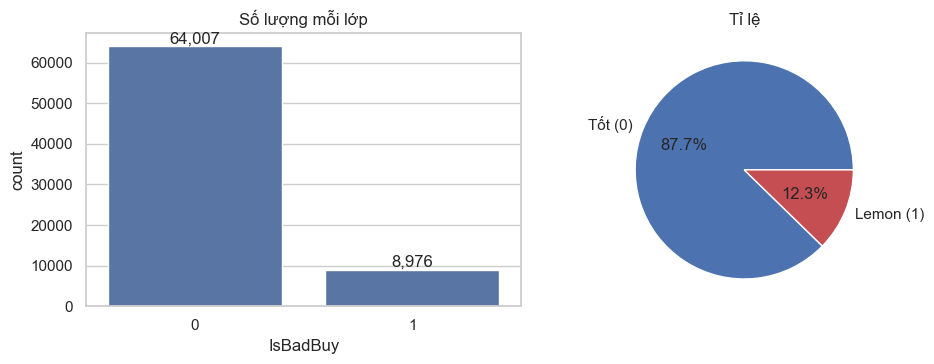

**Kết luận:** lớp lemon chỉ chiếm **12.3%** (tỉ lệ 1:7.1). Một mô hình luôn đoán 'tốt' đã đạt accuracy **87.7%** nhưng vô dụng -> phải dùng F1/PR-AUC và xử lý imbalance.

In [4]:
vc = raw["IsBadBuy"].value_counts().sort_index()
ratio = vc[0] / vc[1]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
sns.countplot(x="IsBadBuy", data=raw, ax=ax[0])
for p in ax[0].patches:
    ax[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax[0].set_title("Số lượng mỗi lớp")
ax[1].pie(vc, labels=["Tốt (0)", "Lemon (1)"], autopct="%.1f%%", colors=["#4c72b0", "#c44e52"])
ax[1].set_title("Tỉ lệ")
plt.tight_layout(); plt.show()
note(f"**Kết luận:** lớp lemon chỉ chiếm **{vc[1]/vc.sum():.1%}** (tỉ lệ 1:{ratio:.1f}). Một mô hình luôn đoán 'tốt' đã đạt accuracy **{vc[0]/vc.sum():.1%}** nhưng vô dụng -> phải dùng F1/PR-AUC và xử lý imbalance.")

### 2.3 Missing values

In [5]:
miss = raw.isna().mean().mul(100).sort_values(ascending=False)
miss = miss[miss > 0]
fig = px.bar(miss.reset_index(), x="index", y=0, labels={"index": "Cột", "0": "% missing"},
             title="Tỉ lệ missing theo cột (chỉ các cột có thiếu)")
fig.update_layout(yaxis_title="% missing", xaxis_title="", height=420)
fig.show()
note(f"**Kết luận:** có **{len(miss)}/{raw.shape[1]}** cột bị thiếu, tổng **{int(raw.isna().sum().sum()):,}** ô. "
     f"`PRIMEUNIT` ({miss.get('PRIMEUNIT',0):.1f}%) và `AUCGUART` ({miss.get('AUCGUART',0):.1f}%) gần như trống -> thiếu có thể mang ý nghĩa (xe không được bảo đảm) nên ta tạo cờ `is_missing` thay vì chỉ điền.")

**Kết luận:** có **20/33** cột bị thiếu, tổng **149,271** ô. `PRIMEUNIT` (95.3%) và `AUCGUART` (95.3%) gần như trống -> thiếu có thể mang ý nghĩa (xe không được bảo đảm) nên ta tạo cờ `is_missing` thay vì chỉ điền.

### 2.4 Numerical: phân phối và outlier

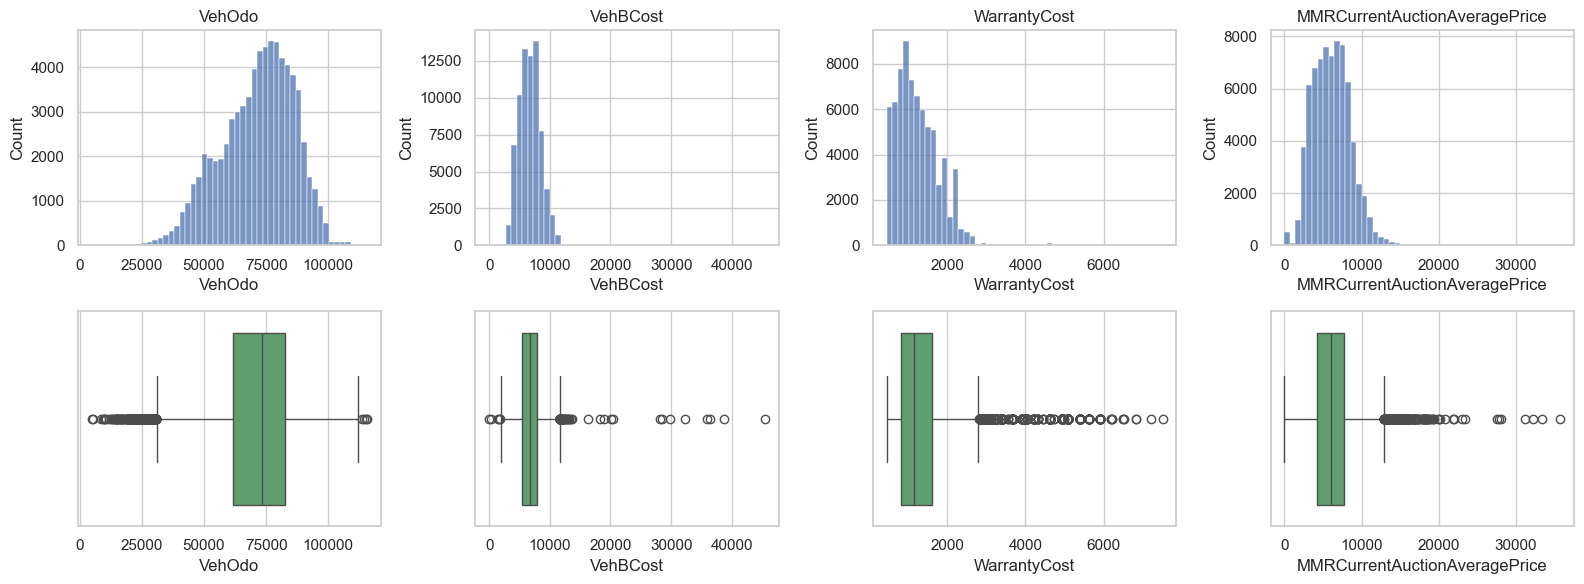

,% outlier theo IQR
VehOdo,0.46
VehBCost,0.24
WarrantyCost,1.15
MMRCurrentAuctionAveragePrice,0.78


**Kết luận:** `WarrantyCost` có đuôi phải dài (outlier 1.15%). Nên dùng **RobustScaler** (median/IQR) thay vì StandardScaler để outlier không kéo lệch thang đo.

In [6]:
num_show = ["VehOdo", "VehBCost", "WarrantyCost", "MMRCurrentAuctionAveragePrice"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for i, c in enumerate(num_show):
    sns.histplot(raw[c].dropna(), bins=50, ax=axes[0, i], color="#4c72b0")
    axes[0, i].set_title(c)
    sns.boxplot(x=raw[c], ax=axes[1, i], color="#55a868")
plt.tight_layout(); plt.show()
q1, q3 = raw[num_show].quantile(.25), raw[num_show].quantile(.75)
iqr = q3 - q1
out_pct = ((raw[num_show] < q1 - 1.5*iqr) | (raw[num_show] > q3 + 1.5*iqr)).mean().mul(100).round(2)
display(out_pct.rename("% outlier theo IQR").to_frame())
note(f"**Kết luận:** `WarrantyCost` có đuôi phải dài (outlier {out_pct['WarrantyCost']}%). Nên dùng **RobustScaler** (median/IQR) thay vì StandardScaler để outlier không kéo lệch thang đo.")

### 2.5 Mục tiêu so với các feature (target vs 2–3 feature)

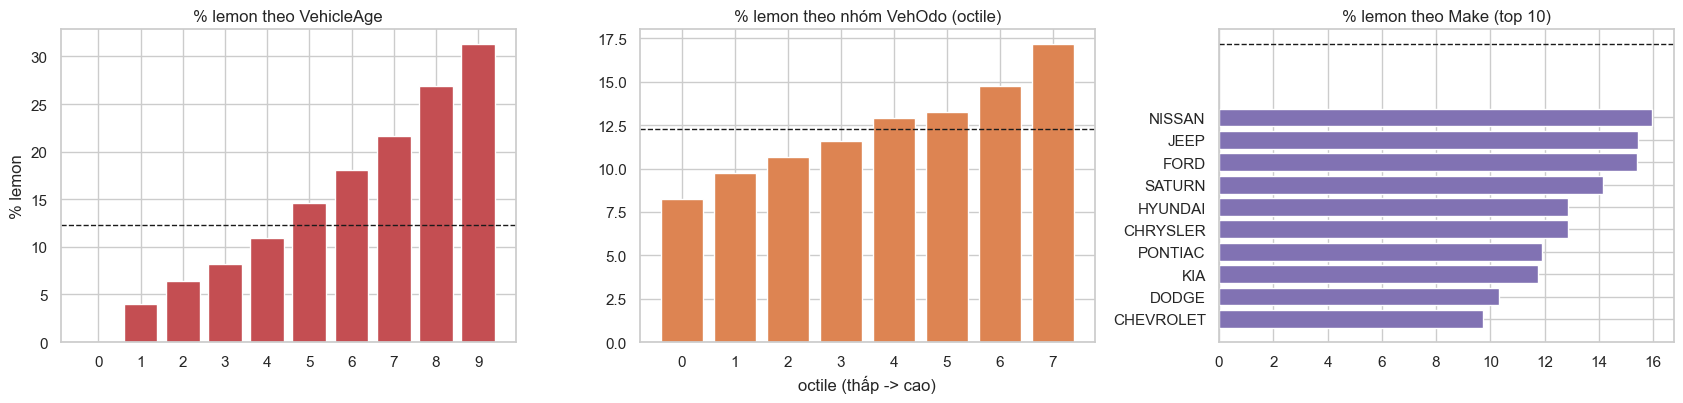

**Kết luận:** xe càng **già** và chạy càng **nhiều km** thì tỉ lệ lemon càng cao: từ **0.0%** (tuổi 0) lên **31.3%** (tuổi 9); octile km thấp nhất **8.2%** vs cao nhất **17.2%**. Hãng cũng khác biệt (từ 9.7% đến 16.0%). Đường nét đứt = mức trung bình toàn bộ.

In [7]:
d = raw.copy()
d["Odo_bin"] = pd.qcut(d["VehOdo"], 8, duplicates="drop")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
r1 = d.groupby("VehicleAge")["IsBadBuy"].mean().mul(100)
ax[0].bar(r1.index.astype(str), r1.values, color="#c44e52"); ax[0].set_title("% lemon theo VehicleAge"); ax[0].set_ylabel("% lemon")
r2 = d.groupby("Odo_bin")["IsBadBuy"].mean().mul(100)
ax[1].bar(range(len(r2)), r2.values, color="#dd8452"); ax[1].set_title("% lemon theo nhóm VehOdo (octile)"); ax[1].set_xlabel("octile (thấp -> cao)")
top = d["Make"].value_counts().head(10).index
r3 = d[d["Make"].isin(top)].groupby("Make")["IsBadBuy"].mean().mul(100).sort_values()
ax[2].barh(r3.index, r3.values, color="#8172b3"); ax[2].set_title("% lemon theo Make (top 10)")
for a in ax: a.axhline(d["IsBadBuy"].mean()*100, color="k", ls="--", lw=1)
plt.tight_layout(); plt.show()
note(f"**Kết luận:** xe càng **già** và chạy càng **nhiều km** thì tỉ lệ lemon càng cao: từ **{r1.iloc[0]:.1f}%** (tuổi {r1.index[0]}) lên **{r1.iloc[-1]:.1f}%** (tuổi {r1.index[-1]}); "
     f"octile km thấp nhất **{r2.iloc[0]:.1f}%** vs cao nhất **{r2.iloc[-1]:.1f}%**. Hãng cũng khác biệt (từ {r3.iloc[0]:.1f}% đến {r3.iloc[-1]:.1f}%). Đường nét đứt = mức trung bình toàn bộ.")

### 2.6 Tương quan giữa các biến số

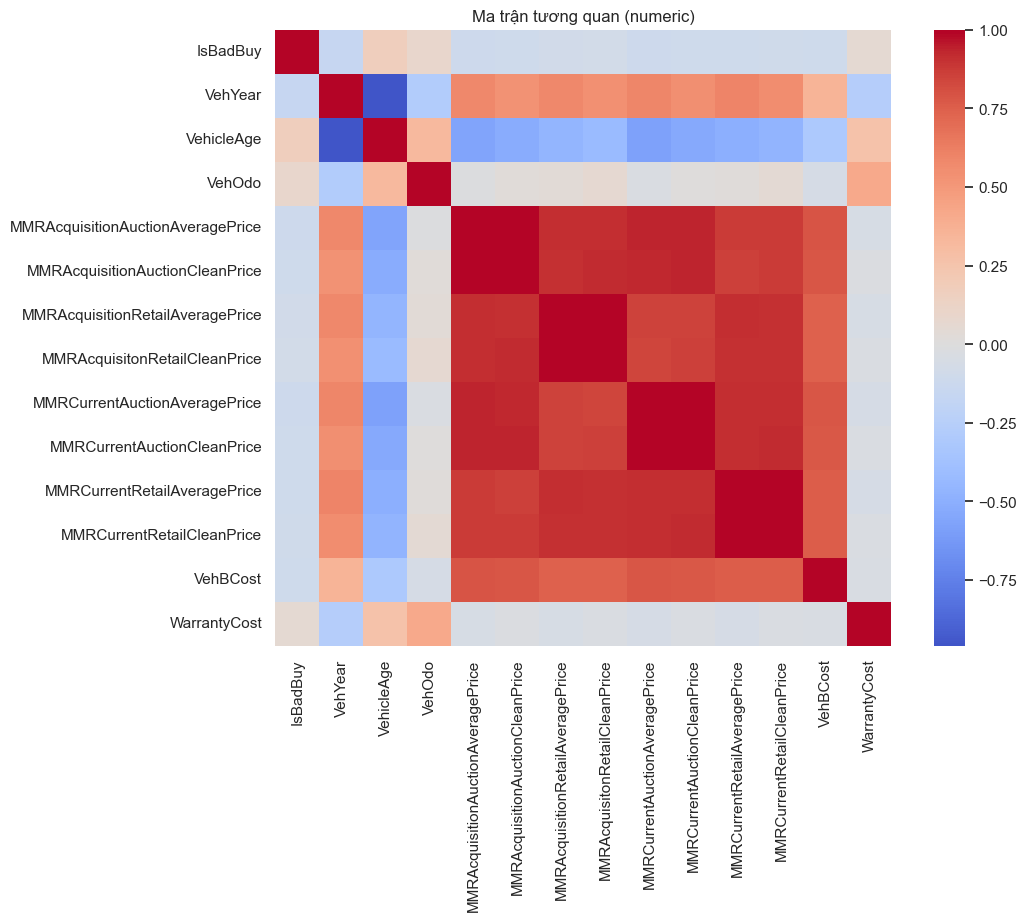

**Kết luận:** 8 cột `MMR*` tương quan gần nhau (|r| lên tới **0.99**) -> đa cộng tuyến, ảnh hưởng mô hình tuyến tính. Tương quan tuyến tính với target đều yếu (cao nhất: `VehicleAge` r=0.17) -> cần mô hình phi tuyến.

In [8]:
num_cols_eda = raw.select_dtypes("number").columns
corr = raw[num_cols_eda].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Ma trận tương quan (numeric)"); plt.show()
tc = corr["IsBadBuy"].drop("IsBadBuy").sort_values(key=abs, ascending=False).head(5)
mmr = [c for c in corr.columns if c.startswith("MMR")]
note(f"**Kết luận:** 8 cột `MMR*` tương quan gần nhau (|r| lên tới **{corr.loc[mmr, mmr].where(~np.eye(len(mmr), dtype=bool)).max().max():.2f}**) -> đa cộng tuyến, ảnh hưởng mô hình tuyến tính. "
     f"Tương quan tuyến tính với target đều yếu (cao nhất: `{tc.index[0]}` r={tc.iloc[0]:.2f}) -> cần mô hình phi tuyến.")

## 3. Chuẩn bị dữ liệu
1. **Feature engineering:** tách `PurchDate` thành năm/tháng; tạo `age_odo = VehOdo/(VehicleAge+1)`, chênh lệch giá `Acq_vs_Cur = MMRAcquisitionAuctionAveragePrice - MMRCurrentAuctionAveragePrice`, `Cost_vs_MMR = VehBCost / MMRCurrentAuctionAveragePrice`; cờ missing cho `PRIMEUNIT`, `AUCGUART`.
2. **Split 60/20/20 train/val/test, stratify theo target** (split *trước* khi fit bất kỳ bộ biến đổi nào -> tránh data leakage).
3. **Missing:** numeric -> median (fit trên train); categorical -> `"missing"`.
4. **Outlier:** giữ nguyên giá trị nhưng dùng RobustScaler (và cây quyết định vốn bền với outlier).
5. **Encoding:** cardinality ≤ 20 -> One-Hot; cardinality cao (Model, Trim, SubModel, BYRNO, VNZIP1, VNST, Make) -> **Frequency encoding** (fit trên train).
6. **Scaling:** RobustScaler cho numeric.

In [9]:
df = raw.copy()
df["PurchYear"] = df["PurchDate"].dt.year
df["PurchMonth"] = df["PurchDate"].dt.month
df["age_odo"] = df["VehOdo"] / (df["VehicleAge"] + 1)
df["Acq_vs_Cur"] = df["MMRAcquisitionAuctionAveragePrice"] - df["MMRCurrentAuctionAveragePrice"]
df["Cost_vs_MMR"] = df["VehBCost"] / df["MMRCurrentAuctionAveragePrice"].replace(0, np.nan)
df["PRIMEUNIT_missing"] = df["PRIMEUNIT"].isna().astype(int)
df["AUCGUART_missing"] = df["AUCGUART"].isna().astype(int)
df = df.drop(columns=["PurchDate"])

y = df.pop("IsBadBuy")
X_train, X_tmp, y_train, y_tmp = train_test_split(df, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=RANDOM_STATE)
print({k: (v.shape[0], round(v.mean(), 4)) for k, v in dict(train=y_train, val=y_val, test=y_test).items()})

{'train': (43789, np.float64(0.123)), 'val': (14597, np.float64(0.123)), 'test': (14597, np.float64(0.123))}


In [10]:
cat_all = X_train.select_dtypes(exclude="number").columns.tolist()
low_cat = [c for c in cat_all if X_train[c].nunique() <= 20]
high_cat = [c for c in cat_all if X_train[c].nunique() > 20]
num_cols = X_train.select_dtypes("number").columns.tolist()
print("numeric:", len(num_cols), "| low-card cat:", low_cat, "\nhigh-card cat:", high_cat)

# Frequency encoding: fit trên TRAIN, áp dụng cho val/test
freq_maps = {c: X_train[c].fillna("missing").value_counts(normalize=True) for c in high_cat}
def add_freq(X):
    X = X.copy()
    for c in high_cat:
        X[c + "_freq"] = X[c].fillna("missing").map(freq_maps[c]).fillna(0.0)
    return X.drop(columns=high_cat)
X_train_f, X_val_f, X_test_f = map(add_freq, (X_train, X_val, X_test))
num_cols_f = num_cols + [c + "_freq" for c in high_cat]

def make_pre(scaler="robust", onehot=True):
    sc = RobustScaler() if scaler == "robust" else StandardScaler()
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", sc)])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                    ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=0.005, sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols_f), ("cat", cat, low_cat)])
pre = make_pre().fit(X_train_f)
print("Số feature sau tiền xử lý:", pre.transform(X_train_f.head()).shape[1])

numeric: 20 | low-card cat: ['Auction', 'Color', 'Transmission', 'WheelTypeID', 'WheelType', 'Nationality', 'Size', 'TopThreeAmericanName', 'PRIMEUNIT', 'AUCGUART', 'IsOnlineSale'] 
high-card cat: ['Make', 'Model', 'Trim', 'SubModel', 'BYRNO', 'VNZIP1', 'VNST']


Số feature sau tiền xử lý: 86


### 3.1 So sánh phân phối trước/sau scaling

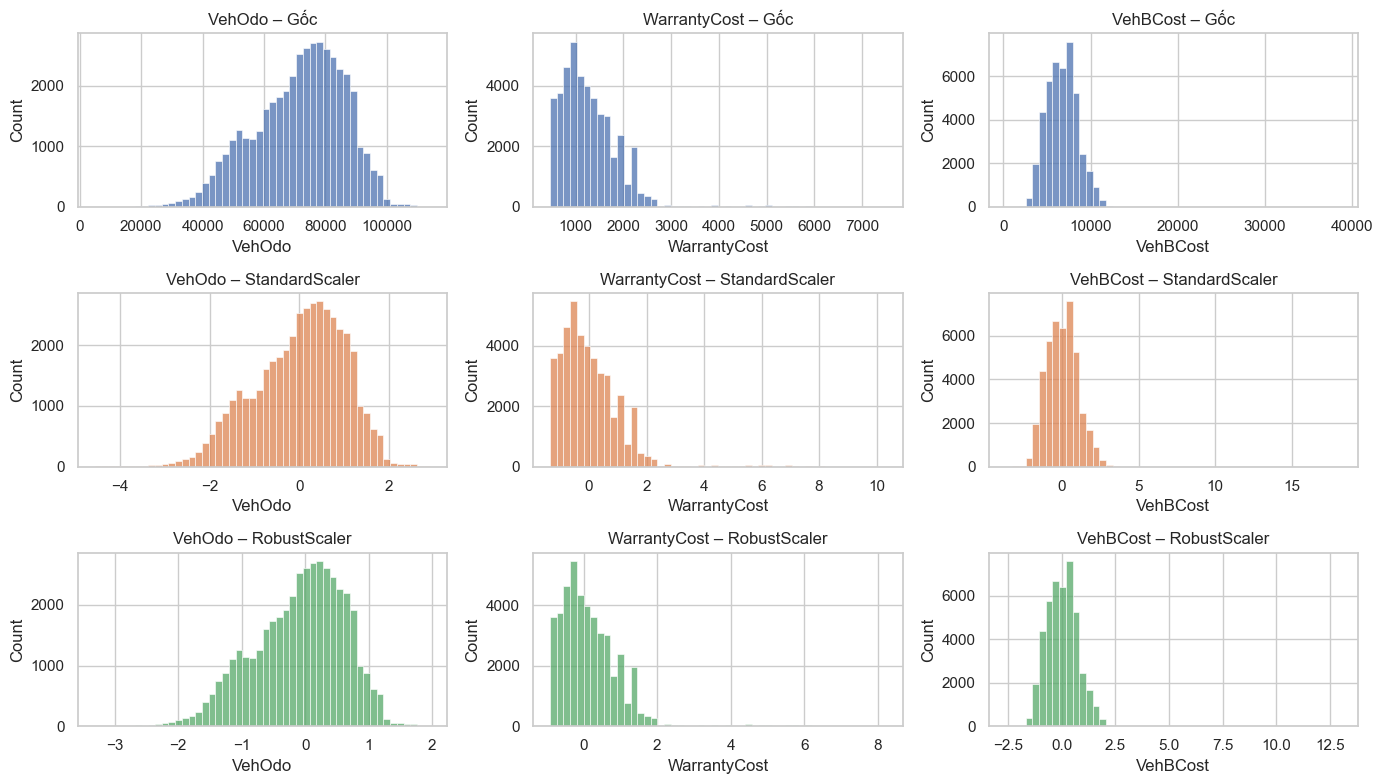

**Kết luận:** với `WarrantyCost`, độ lệch chuẩn = **602** trong khi 'sigma theo IQR' = **571** (tỉ lệ 1.05). Tỉ lệ > 1 nghĩa là outlier làm phồng độ lệch chuẩn nên StandardScaler nén phần lớn dữ liệu vào vùng hẹp hơn; RobustScaler chuẩn hóa theo median/IQR nên không bị outlier chi phối. Cả hai đều giữ nguyên hình dạng phân phối (lệch phải), chỉ đổi thang đo.

In [11]:
cols = ["VehOdo", "WarrantyCost", "VehBCost"]
sub = X_train_f[cols].copy()
sub_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(sub), columns=cols)
rob = pd.DataFrame(RobustScaler().fit_transform(sub_imp), columns=cols)
std = pd.DataFrame(StandardScaler().fit_transform(sub_imp), columns=cols)
fig, axes = plt.subplots(3, 3, figsize=(14, 8))
for j, c in enumerate(cols):
    for i, (nm, dd) in enumerate([("Gốc", sub_imp), ("StandardScaler", std), ("RobustScaler", rob)]):
        sns.histplot(dd[c], bins=50, ax=axes[i, j], color=["#4c72b0", "#dd8452", "#55a868"][i])
        axes[i, j].set_title(f"{c} – {nm}")
plt.tight_layout(); plt.show()
w = sub_imp["WarrantyCost"]
sig_iqr = (w.quantile(.75) - w.quantile(.25)) / 1.349
note(f"**Kết luận:** với `WarrantyCost`, độ lệch chuẩn = **{w.std():.0f}** trong khi 'sigma theo IQR' = **{sig_iqr:.0f}** (tỉ lệ {w.std()/sig_iqr:.2f}). "
     f"Tỉ lệ > 1 nghĩa là outlier làm phồng độ lệch chuẩn nên StandardScaler nén phần lớn dữ liệu vào vùng hẹp hơn; RobustScaler chuẩn hóa theo median/IQR nên không bị outlier chi phối. Cả hai đều giữ nguyên hình dạng phân phối (lệch phải), chỉ đổi thang đo.")

## 4. Mô hình hóa
Huấn luyện 6 cấu hình để so sánh có chủ đích:

| # | Mô hình | Mục đích |
|---|---|---|
| A | Logistic Regression (baseline) | Mốc tham chiếu |
| B | Logistic Regression + `class_weight=balanced` | Tác động của xử lý imbalance |
| C | Random Forest + `class_weight=balanced_subsample` | Mô hình phi tuyến |
| D | HistGradientBoosting (không xử lý imbalance) | Boosting |
| E | HistGradientBoosting + `class_weight=balanced` | Boosting + imbalance |
| F | E + **chỉnh ngưỡng** theo F1 trên validation | Ngưỡng 0.5 không phù hợp lớp hiếm |

In [12]:
def evaluate(name, proba, y_true, thr=0.5):
    pred = (proba >= thr).astype(int)
    return dict(model=name, thr=round(thr, 3), accuracy=(pred == y_true).mean(),
                balanced_acc=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                ROC_AUC=roc_auc_score(y_true, proba), PR_AUC=average_precision_score(y_true, proba))

models = {
    "A. LogReg (baseline)": Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=1000))]),
    "B. LogReg + balanced": Pipeline([("pre", make_pre()), ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "C. RandomForest + balanced": Pipeline([("pre", make_pre()), ("clf", RandomForestClassifier(
        n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))]),
    "D. HistGB": Pipeline([("pre", make_pre()), ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
    "E. HistGB + balanced": Pipeline([("pre", make_pre()), ("clf", HistGradientBoostingClassifier(
        class_weight="balanced", random_state=RANDOM_STATE))]),
}
val_proba, test_proba, rows_val, rows_test = {}, {}, [], []
for n, m in models.items():
    m.fit(X_train_f, y_train)
    val_proba[n] = m.predict_proba(X_val_f)[:, 1]
    test_proba[n] = m.predict_proba(X_test_f)[:, 1]
    rows_val.append(evaluate(n, val_proba[n], y_val))
    rows_test.append(evaluate(n, test_proba[n], y_test))

# F: chọn ngưỡng tối ưu F1 trên VALIDATION, áp dụng lên TEST
n = "E. HistGB + balanced"
pr, rc, th = precision_recall_curve(y_val, val_proba[n])
f1s = 2 * pr * rc / (pr + rc + 1e-9)
best_thr = th[np.argmax(f1s[:-1])]
nF = "F. HistGB + balanced + tuned thr"
rows_val.append(evaluate(nF, val_proba[n], y_val, best_thr))
rows_test.append(evaluate(nF, test_proba[n], y_test, best_thr))
test_proba[nF] = test_proba[n]

val_df = pd.DataFrame(rows_val).set_index("model")
res = pd.DataFrame(rows_test).set_index("model")
print("== Validation =="); display(val_df.round(4))
print("== Test =="); display(res.round(4).style.background_gradient(cmap="Greens", subset=["F1", "ROC_AUC", "PR_AUC"]))

== Validation ==


,thr,accuracy,balanced_acc,precision,recall,F1,ROC_AUC,PR_AUC
model,,,,,,,,
A. LogReg (baseline),0.500,0.8955,0.6094,0.7415,0.2301,0.3512,0.7585,0.4462
B. LogReg + balanced,0.500,0.7460,0.6909,0.2685,0.6178,0.3743,0.7623,0.4427
C. RandomForest + balanced,0.500,0.8952,0.6354,0.6701,0.2908,0.4056,0.7737,0.4865
D. HistGB,0.500,0.9025,0.6180,0.8780,0.2407,0.3778,0.7825,0.5035
E. HistGB + balanced,0.500,0.7766,0.7062,0.3001,0.6128,0.4029,0.7819,0.4976
F. HistGB + balanced + tuned thr,0.611,0.8585,0.6875,0.4296,0.4607,0.4446,0.7819,0.4976


== Test ==


,thr,accuracy,balanced_acc,precision,recall,F1,ROC_AUC,PR_AUC
model,,,,,,,,
A. LogReg (baseline),0.500000,0.894700,0.609000,0.727100,0.230100,0.349600,0.744700,0.425700
B. LogReg + balanced,0.500000,0.734700,0.678000,0.255100,0.602800,0.358500,0.747400,0.420800
C. RandomForest + balanced,0.500000,0.894100,0.632600,0.660200,0.285800,0.398900,0.760400,0.470100
D. HistGB,0.500000,0.902000,0.615600,0.879400,0.235700,0.371700,0.775000,0.492600
E. HistGB + balanced,0.500000,0.766900,0.694200,0.285900,0.597800,0.386800,0.772700,0.481400
F. HistGB + balanced + tuned thr,0.611000,0.852500,0.675200,0.407600,0.440100,0.423300,0.772700,0.481400


### 4.1 So sánh mô hình (baseline vs mô hình mở rộng)

In [13]:
m = res[["balanced_acc", "recall", "precision", "F1", "ROC_AUC", "PR_AUC"]].reset_index().melt("model")
fig = px.bar(m, x="variable", y="value", color="model", barmode="group", title="Metric trên tập TEST",
             labels={"variable": "Metric", "value": "Giá trị"}, height=450)
fig.show()
base, best = res.loc["A. LogReg (baseline)"], res.loc[nF]
best_name = res["F1"].idxmax()
note(f"**Kết luận:** (1) Baseline A có accuracy **{base.accuracy:.3f}** nhưng recall chỉ **{base.recall:.3f}** / F1 **{base.F1:.3f}** – bị lớp đa số chi phối. "
     f"(2) `class_weight=balanced` (B) tăng recall lên **{res.loc['B. LogReg + balanced'].recall:.3f}** nhưng precision giảm xuống **{res.loc['B. LogReg + balanced'].precision:.3f}**. "
     f"(3) Boosting D đạt PR-AUC **{res.loc['D. HistGB'].PR_AUC:.3f}** so với LogReg **{base.PR_AUC:.3f}**. "
     f"(4) Chỉnh ngưỡng (F, thr={best_thr:.2f}) cho F1 = **{best.F1:.3f}**. Mô hình F1 cao nhất trên test: **{best_name}** (F1={res['F1'].max():.3f}).")

**Kết luận:** (1) Baseline A có accuracy **0.895** nhưng recall chỉ **0.230** / F1 **0.350** – bị lớp đa số chi phối. (2) `class_weight=balanced` (B) tăng recall lên **0.603** nhưng precision giảm xuống **0.255**. (3) Boosting D đạt PR-AUC **0.493** so với LogReg **0.426**. (4) Chỉnh ngưỡng (F, thr=0.61) cho F1 = **0.423**. Mô hình F1 cao nhất trên test: **F. HistGB + balanced + tuned thr** (F1=0.423).

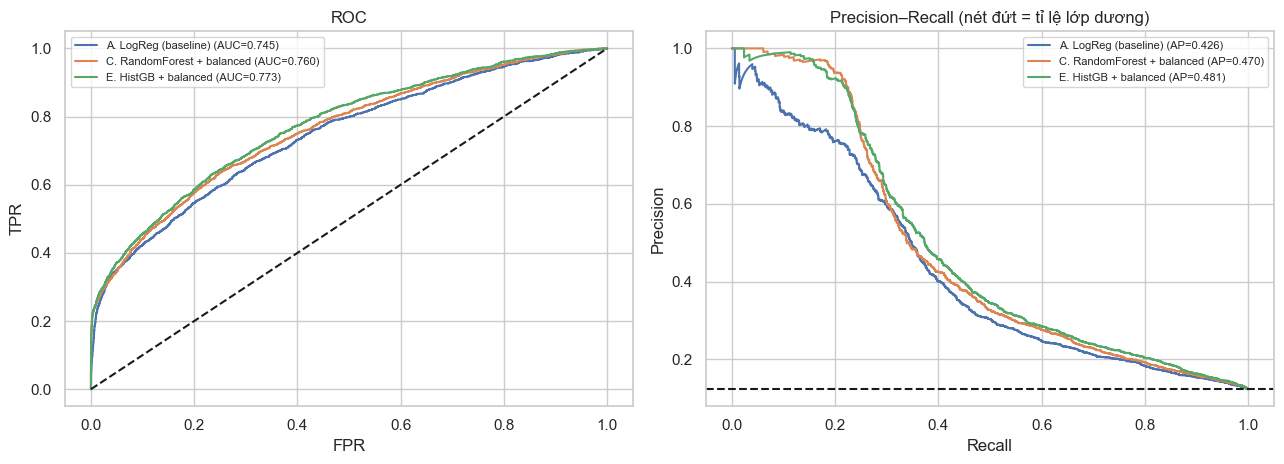

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for n in ["A. LogReg (baseline)", "C. RandomForest + balanced", "E. HistGB + balanced"]:
    fpr, tpr, _ = roc_curve(y_test, test_proba[n]); ax[0].plot(fpr, tpr, label=f"{n} (AUC={res.loc[n,'ROC_AUC']:.3f})")
    p, r, _ = precision_recall_curve(y_test, test_proba[n]); ax[1].plot(r, p, label=f"{n} (AP={res.loc[n,'PR_AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend(fontsize=8)
ax[1].axhline(y_test.mean(), color="k", ls="--"); ax[1].set_title("Precision–Recall (nét đứt = tỉ lệ lớp dương)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.2 Confusion matrix: baseline vs mô hình cuối

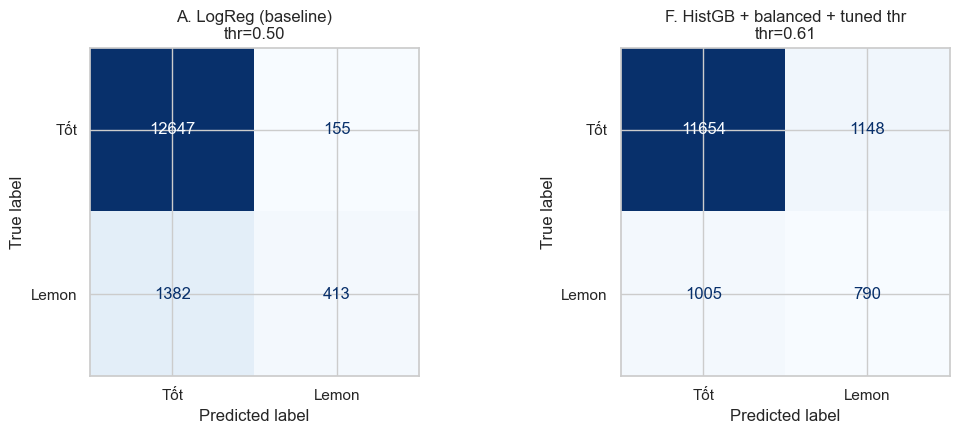

**Kết luận:** số lemon bắt được tăng từ **413** (baseline) lên **790** (mô hình cuối) trên tổng **1795** lemon thật; đổi lại số xe tốt bị cảnh báo nhầm tăng từ **155** lên **1148**. Đây là trade-off: chi phí bỏ sót lemon thường cao hơn chi phí kiểm tra thêm xe.

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, (n, thr) in zip(ax, [("A. LogReg (baseline)", 0.5), (nF, best_thr)]):
    pred = (test_proba[n] >= thr).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Tốt", "Lemon"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"{n}\nthr={thr:.2f}")
plt.tight_layout(); plt.show()
cmA = confusion_matrix(y_test, (test_proba["A. LogReg (baseline)"] >= .5).astype(int))
cmF = confusion_matrix(y_test, (test_proba[nF] >= best_thr).astype(int))
note(f"**Kết luận:** số lemon bắt được tăng từ **{cmA[1,1]}** (baseline) lên **{cmF[1,1]}** (mô hình cuối) trên tổng **{cmF[1].sum()}** lemon thật; "
     f"đổi lại số xe tốt bị cảnh báo nhầm tăng từ **{cmA[0,1]}** lên **{cmF[0,1]}**. Đây là trade-off: chi phí bỏ sót lemon thường cao hơn chi phí kiểm tra thêm xe.")

### 4.3 Feature importance (permutation importance, mô hình E trên test)

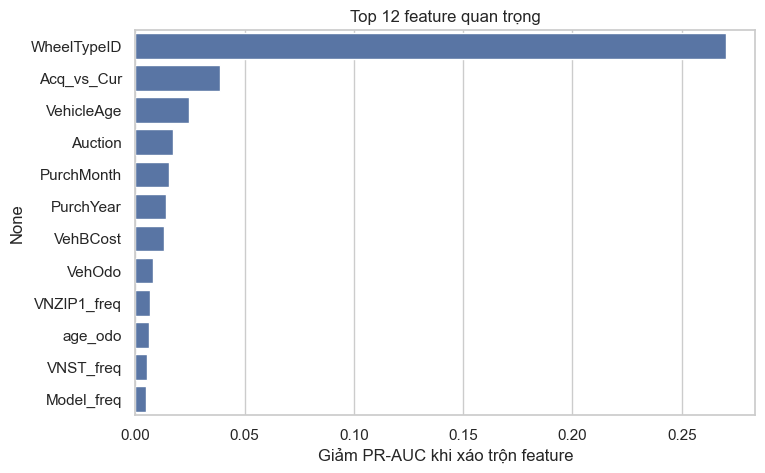

**Kết luận:** 3 feature quan trọng nhất là **WheelTypeID, Acq_vs_Cur, VehicleAge** (giảm PR-AUC 0.270, 0.039, 0.025). Lưu ý `WheelTypeID` (thiếu giá trị ở một nhóm xe) là tín hiệu rất mạnh; cần cẩn trọng vì nếu cách thu thập ID này thay đổi khi triển khai thật thì mô hình sẽ lệch.

In [16]:
mE = models["E. HistGB + balanced"]
idx = X_test_f.sample(6000, random_state=RANDOM_STATE).index
pi = permutation_importance(mE, X_test_f.loc[idx], y_test.loc[idx], scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test_f.columns).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 5)); sns.barplot(x=imp.values, y=imp.index, color="#4c72b0")
plt.xlabel("Giảm PR-AUC khi xáo trộn feature"); plt.title("Top 12 feature quan trọng"); plt.show()
note(f"**Kết luận:** 3 feature quan trọng nhất là **{', '.join(imp.index[:3])}** (giảm PR-AUC {imp.iloc[0]:.3f}, {imp.iloc[1]:.3f}, {imp.iloc[2]:.3f}). "
     "Lưu ý `WheelTypeID` (thiếu giá trị ở một nhóm xe) là tín hiệu rất mạnh; cần cẩn trọng vì nếu cách thu thập ID này thay đổi khi triển khai thật thì mô hình sẽ lệch.")

## 5. Tổng kết và mở rộng
Phần này được điền tự động từ bảng metric để kết luận luôn khớp số liệu trong report.

In [17]:
best_by_pr = res["PR_AUC"].idxmax()
note(f"""
### Kết quả chính (tập test, {len(y_test):,} mẫu)
| Mô hình | F1 | Recall | PR-AUC | ROC-AUC |
|---|---|---|---|---|
""" + "\n".join(f"| {i} | {r.F1:.3f} | {r.recall:.3f} | {r.PR_AUC:.3f} | {r.ROC_AUC:.3f} |" for i, r in res.iterrows()) + f"""

- **Mô hình tốt nhất theo PR-AUC:** {best_by_pr} ({res.loc[best_by_pr,'PR_AUC']:.3f}); theo F1: {res['F1'].idxmax()} ({res['F1'].max():.3f}).
- So với baseline: F1 **{base.F1:.3f} → {res['F1'].max():.3f}** (gấp {res['F1'].max()/max(base.F1,1e-9):.1f} lần), recall **{base.recall:.3f} → {res.loc[res['F1'].idxmax()].recall:.3f}**.
- **Accuracy gây hiểu lầm:** baseline accuracy {base.accuracy:.3f} cao nhưng F1 thấp, do dữ liệu lệch lớp.

### Hạn chế
- ROC-AUC/PR-AUC vẫn ở mức vừa phải -> dữ liệu có nhiễu, thông tin trong bảng không đủ phân biệt hoàn toàn (không có thông tin kiểm định cơ khí).
- Frequency encoding làm mất thông tin về *danh tính* của Model/Trim; chưa tinh chỉnh siêu tham số (chỉ dùng mặc định).
- Chia ngẫu nhiên, chưa kiểm tra drift theo thời gian (`PurchDate`).

### Hướng mở rộng
- Target encoding có cross-fitting; tối ưu siêu tham số (RandomizedSearchCV); SMOTE / cost-sensitive threshold theo chi phí kinh doanh thật.
- Chia theo thời gian để kiểm tra mô hình có bền khi triển khai; SHAP để giải thích từng dự đoán.
""")


### Kết quả chính (tập test, 14,597 mẫu)
| Mô hình | F1 | Recall | PR-AUC | ROC-AUC |
|---|---|---|---|---|
| A. LogReg (baseline) | 0.350 | 0.230 | 0.426 | 0.745 |
| B. LogReg + balanced | 0.358 | 0.603 | 0.421 | 0.747 |
| C. RandomForest + balanced | 0.399 | 0.286 | 0.470 | 0.760 |
| D. HistGB | 0.372 | 0.236 | 0.493 | 0.775 |
| E. HistGB + balanced | 0.387 | 0.598 | 0.481 | 0.773 |
| F. HistGB + balanced + tuned thr | 0.423 | 0.440 | 0.481 | 0.773 |

- **Mô hình tốt nhất theo PR-AUC:** D. HistGB (0.493); theo F1: F. HistGB + balanced + tuned thr (0.423).
- So với baseline: F1 **0.350 → 0.423** (gấp 1.2 lần), recall **0.230 → 0.440**.
- **Accuracy gây hiểu lầm:** baseline accuracy 0.895 cao nhưng F1 thấp, do dữ liệu lệch lớp.

### Hạn chế
- ROC-AUC/PR-AUC vẫn ở mức vừa phải -> dữ liệu có nhiễu, thông tin trong bảng không đủ phân biệt hoàn toàn (không có thông tin kiểm định cơ khí).
- Frequency encoding làm mất thông tin về *danh tính* của Model/Trim; chưa tinh chỉnh siêu tham số (chỉ dùng mặc định).
- Chia ngẫu nhiên, chưa kiểm tra drift theo thời gian (`PurchDate`).

### Hướng mở rộng
- Target encoding có cross-fitting; tối ưu siêu tham số (RandomizedSearchCV); SMOTE / cost-sensitive threshold theo chi phí kinh doanh thật.
- Chia theo thời gian để kiểm tra mô hình có bền khi triển khai; SHAP để giải thích từng dự đoán.
